In [81]:
# import kagglehub
# # let's authintificate ourselves with API token
# kagglehub.login()

In [82]:
# playground_series_s5e1_path = kagglehub.competition_download('playground-series-s5e1')
# playground_series_s5e1_path

In [83]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('./.'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

././train.csv
././submission.csv
././test.csv
././playground-s5e1.ipynb
././playground-series-s5e1-mess.ipynb
././catboost_info/catboost_training.json
././catboost_info/time_left.tsv
././catboost_info/learn_error.tsv
././catboost_info/learn/events.out.tfevents


In [84]:
import sklearn
print(sklearn.__version__)

1.6.0


In [143]:
df_train = pd.read_csv('train.csv')
df_train

,id,date,country,store,product,num_sold
0,0,2010-01-01,Canada,Discount Stickers,Holographic Goose,NaN
1,1,2010-01-01,Canada,Discount Stickers,Kaggle,973.0
2,2,2010-01-01,Canada,Discount Stickers,Kaggle Tiers,906.0
3,3,2010-01-01,Canada,Discount Stickers,Kerneler,423.0
4,4,2010-01-01,Canada,Discount Stickers,Kerneler Dark Mode,491.0
...,...,...,...,...,...,...
230125,230125,2016-12-31,Singapore,Premium Sticker Mart,Holographic Goose,466.0
230126,230126,2016-12-31,Singapore,Premium Sticker Mart,Kaggle,2907.0
230127,230127,2016-12-31,Singapore,Premium Sticker Mart,Kaggle Tiers,2299.0
230128,230128,2016-12-31,Singapore,Premium Sticker Mart,Kerneler,1242.0


In [144]:
df_train.drop('id', axis=1, inplace=True)

In [124]:
print(df_train.count())

date        230130
country     230130
store       230130
product     230130
num_sold    221259
dtype: int64


In [146]:
df_train['year-month'] = df_train['date'].apply(lambda x: x[:7])
df = df_train[(df_train['country'] == 'Canada') & (df_train['store'] == 'Discount Stickers') & (df_train['product'] == 'Holographic Goose')]
df = df[['year-month', 'num_sold']]
df_agg = df.groupby(['year-month']).sum()
df_agg

,num_sold
year-month,
2010-01,0.0
2010-02,0.0
2010-03,0.0
2010-04,0.0
2010-05,0.0
...,...
2016-08,0.0
2016-09,0.0
2016-10,0.0


ValueError: Could not interpret value `total_sold` for `y`. An entry with this name does not appear in `data`.

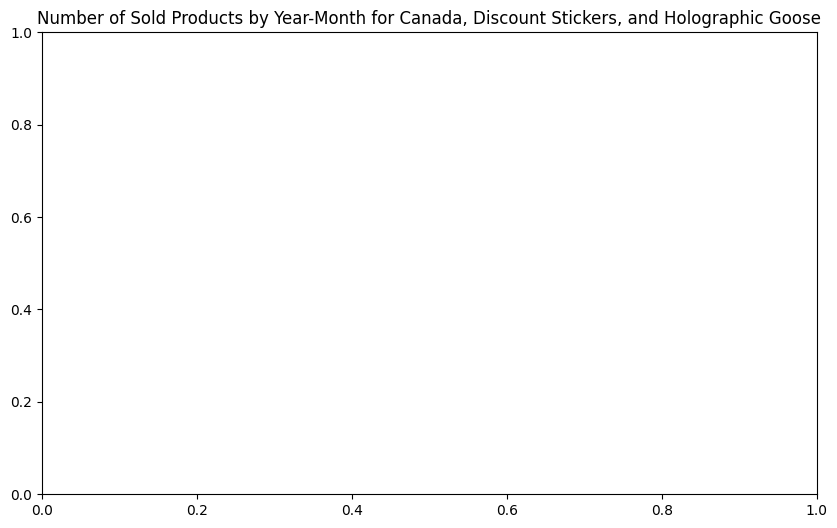

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

for country in df_train.country.unique():
    for store in df_train.store.unique():
        for product in df_train['product'].unique():
            plt.figure(figsize=(10, 6))
            plt.title(f'Number of Sold Products by Year-Month for {country}, {store}, and {product}')
            df = df_train[(df_train['country'] == country) & (df_train['store'] == store) & (df_train['product'] == product)]
            df = df[['year-month', 'num_sold']]
            df_agg = df.groupby(['year-month']).sum()
            sns.lineplot(x='year-month', y='num_sold', data=df_agg)
            plt.show()


In [ ]:

df_train['day'] = df_train['date'].apply(lambda x: int(x[8:10]))
df_train['date'] = pd.to_datetime(df_train['date'])
df_train['day of year'] = df_train['date'].dt.dayofyear
df_train['day of week'] = df_train['date'].dt.weekday
df_train['sin day of week'] = np.sin(2 * np.pi * df_train['day of week'] / 7)
df_train['cos day of week'] = np.cos(2 * np.pi * df_train['day of week'] / 7)
df_train['sin day of month'] = np.sin(2 * np.pi * df_train['day'] / 30)
df_train['cos day of month'] = np.cos(2 * np.pi * df_train['day'] / 30)
df_train['sin of month'] = np.sin(2 * np.pi * df_train['month'] / 12)
df_train['cos of month'] = np.cos(2 * np.pi * df_train['month'] / 12)
#df_train['seconds since 1970'] = df_train['date'].astype('int64') // 10 ** 9
df_train.drop('date', axis=1, inplace=True) #
df_train

,country,store,product,num_sold,year,month,day,day of year,day of week,sin day of week,cos day of week,sin day of month,cos day of month,sin of month,cos of month
0,Canada,Discount Stickers,Holographic Goose,NaN,2010,1,1,1,4,-0.433884,-0.900969,0.207912,0.978148,5.000000e-01,0.866025
1,Canada,Discount Stickers,Kaggle,973.0,2010,1,1,1,4,-0.433884,-0.900969,0.207912,0.978148,5.000000e-01,0.866025
2,Canada,Discount Stickers,Kaggle Tiers,906.0,2010,1,1,1,4,-0.433884,-0.900969,0.207912,0.978148,5.000000e-01,0.866025
3,Canada,Discount Stickers,Kerneler,423.0,2010,1,1,1,4,-0.433884,-0.900969,0.207912,0.978148,5.000000e-01,0.866025
4,Canada,Discount Stickers,Kerneler Dark Mode,491.0,2010,1,1,1,4,-0.433884,-0.900969,0.207912,0.978148,5.000000e-01,0.866025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
230125,Singapore,Premium Sticker Mart,Holographic Goose,466.0,2016,12,31,366,5,-0.974928,-0.222521,0.207912,0.978148,-2.449294e-16,1.000000
230126,Singapore,Premium Sticker Mart,Kaggle,2907.0,2016,12,31,366,5,-0.974928,-0.222521,0.207912,0.978148,-2.449294e-16,1.000000
230127,Singapore,Premium Sticker Mart,Kaggle Tiers,2299.0,2016,12,31,366,5,-0.974928,-0.222521,0.207912,0.978148,-2.449294e-16,1.000000
230128,Singapore,Premium Sticker Mart,Kerneler,1242.0,2016,12,31,366,5,-0.974928,-0.222521,0.207912,0.978148,-2.449294e-16,1.000000


In [89]:
# let's drop all rows with NaN values in the target column
df_train.dropna(subset=['num_sold'], inplace=True)

In [90]:
target = pd.DataFrame(df_train['num_sold'].astype('float64'))
target

,num_sold
1,973.0
2,906.0
3,423.0
4,491.0
5,300.0
...,...
230125,466.0
230126,2907.0
230127,2299.0
230128,1242.0


In [91]:
df_train.drop('num_sold', axis=1, inplace=True)
X = df_train.copy()

In [92]:
from catboost import CatBoostRegressor, Pool

train_pool = Pool(df_train, target, cat_features=['country', 'store', 'product'])

regressor = CatBoostRegressor(iterations=300, loss_function='MAPE', verbose=True)

In [93]:
#regressor.fit(train_pool)

In [94]:
df_test = pd.read_csv('test.csv')
ids = df_test['id']
df_test

,id,date,country,store,product
0,230130,2017-01-01,Canada,Discount Stickers,Holographic Goose
1,230131,2017-01-01,Canada,Discount Stickers,Kaggle
2,230132,2017-01-01,Canada,Discount Stickers,Kaggle Tiers
3,230133,2017-01-01,Canada,Discount Stickers,Kerneler
4,230134,2017-01-01,Canada,Discount Stickers,Kerneler Dark Mode
...,...,...,...,...,...
98545,328675,2019-12-31,Singapore,Premium Sticker Mart,Holographic Goose
98546,328676,2019-12-31,Singapore,Premium Sticker Mart,Kaggle
98547,328677,2019-12-31,Singapore,Premium Sticker Mart,Kaggle Tiers
98548,328678,2019-12-31,Singapore,Premium Sticker Mart,Kerneler


In [95]:
df_test.drop('id', axis=1, inplace=True)

In [96]:
df_test['year'] = df_test['date'].apply(lambda x: int(x[:4]))
df_test['month'] = df_test['date'].apply(lambda x: int(x[5:7]))
df_test['day'] = df_test['date'].apply(lambda x: int(x[8:10]))
df_test['date'] = pd.to_datetime(df_test['date'])
df_test['day of year'] = df_test['date'].dt.dayofyear
df_test['day of week'] = df_test['date'].dt.weekday
df_test['sin day of week'] = np.sin(2 * np.pi * df_test['day of week'] / 7)
df_test['cos day of week'] = np.cos(2 * np.pi * df_test['day of week'] / 7)
df_test['sin day of month'] = np.sin(2 * np.pi * df_test['day'] / 30)
df_test['cos day of month'] = np.cos(2 * np.pi * df_test['day'] / 30)
df_test['sin of month'] = np.sin(2 * np.pi * df_test['month'] / 12)
df_test['cos of month'] = np.cos(2 * np.pi * df_test['month'] / 12)
#df_test['seconds since 1970'] = df_test['date'].astype('int64') // 10 ** 9
df_test.drop('date', axis=1, inplace=True) #
df_test

,country,store,product,year,month,day,day of year,day of week,sin day of week,cos day of week,sin day of month,cos day of month,sin of month,cos of month
0,Canada,Discount Stickers,Holographic Goose,2017,1,1,1,6,-0.781831,0.62349,0.207912,0.978148,5.000000e-01,0.866025
1,Canada,Discount Stickers,Kaggle,2017,1,1,1,6,-0.781831,0.62349,0.207912,0.978148,5.000000e-01,0.866025
2,Canada,Discount Stickers,Kaggle Tiers,2017,1,1,1,6,-0.781831,0.62349,0.207912,0.978148,5.000000e-01,0.866025
3,Canada,Discount Stickers,Kerneler,2017,1,1,1,6,-0.781831,0.62349,0.207912,0.978148,5.000000e-01,0.866025
4,Canada,Discount Stickers,Kerneler Dark Mode,2017,1,1,1,6,-0.781831,0.62349,0.207912,0.978148,5.000000e-01,0.866025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98545,Singapore,Premium Sticker Mart,Holographic Goose,2019,12,31,365,1,0.781831,0.62349,0.207912,0.978148,-2.449294e-16,1.000000
98546,Singapore,Premium Sticker Mart,Kaggle,2019,12,31,365,1,0.781831,0.62349,0.207912,0.978148,-2.449294e-16,1.000000
98547,Singapore,Premium Sticker Mart,Kaggle Tiers,2019,12,31,365,1,0.781831,0.62349,0.207912,0.978148,-2.449294e-16,1.000000
98548,Singapore,Premium Sticker Mart,Kerneler,2019,12,31,365,1,0.781831,0.62349,0.207912,0.978148,-2.449294e-16,1.000000


In [97]:
# pred = regressor.predict(df_test)

In [98]:
def season(month):
    match month:
        case 1 | 12: 
            return 'winter'
        case 2 | 3 | 4 | 5:
            return 'spring'
        case 6 | 7 | 8 :
            return 'summer'
        case _:
            return 'autumn'

df_train['season'] = df_train['month'].apply(season) 

In [99]:

df_train['sin day of year'] = np.sin(2 * np.pi * df_train['day of year'] / 365)
df_train['cos day of year'] = np.cos(2 * np.pi * df_train['day of year'] / 365)


df_train['day'] = df_train['day'].astype('category')
df_train['month'] = df_train['month'].astype('category')


df_train['day of year'] = df_train['day of year'].astype('category')
df_train['day of week'] = df_train['day of week'].astype('category')


df_train

,country,store,product,year,month,day,day of year,day of week,sin day of week,cos day of week,sin day of month,cos day of month,sin of month,cos of month,season,sin day of year,cos day of year
1,Canada,Discount Stickers,Kaggle,2010,1,1,1,4,-0.433884,-0.900969,0.207912,0.978148,5.000000e-01,0.866025,winter,0.017213,0.999852
2,Canada,Discount Stickers,Kaggle Tiers,2010,1,1,1,4,-0.433884,-0.900969,0.207912,0.978148,5.000000e-01,0.866025,winter,0.017213,0.999852
3,Canada,Discount Stickers,Kerneler,2010,1,1,1,4,-0.433884,-0.900969,0.207912,0.978148,5.000000e-01,0.866025,winter,0.017213,0.999852
4,Canada,Discount Stickers,Kerneler Dark Mode,2010,1,1,1,4,-0.433884,-0.900969,0.207912,0.978148,5.000000e-01,0.866025,winter,0.017213,0.999852
5,Canada,Stickers for Less,Holographic Goose,2010,1,1,1,4,-0.433884,-0.900969,0.207912,0.978148,5.000000e-01,0.866025,winter,0.017213,0.999852
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
230125,Singapore,Premium Sticker Mart,Holographic Goose,2016,12,31,366,5,-0.974928,-0.222521,0.207912,0.978148,-2.449294e-16,1.000000,winter,0.017213,0.999852
230126,Singapore,Premium Sticker Mart,Kaggle,2016,12,31,366,5,-0.974928,-0.222521,0.207912,0.978148,-2.449294e-16,1.000000,winter,0.017213,0.999852
230127,Singapore,Premium Sticker Mart,Kaggle Tiers,2016,12,31,366,5,-0.974928,-0.222521,0.207912,0.978148,-2.449294e-16,1.000000,winter,0.017213,0.999852
230128,Singapore,Premium Sticker Mart,Kerneler,2016,12,31,366,5,-0.974928,-0.222521,0.207912,0.978148,-2.449294e-16,1.000000,winter,0.017213,0.999852


In [100]:
from sklearn.pipeline import Pipeline

from sklearn.base import BaseEstimator, TransformerMixin

class DropNaNColumns(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.5):
        self.threshold = threshold
        self.columns_to_drop_ = None

    def fit(self, X, y=None):
        # Calculate the percentage of NaN values in each column
        nan_percentage = X.isna().mean()
        # Identify columns to drop
        self.columns_to_drop_ = nan_percentage[nan_percentage > self.threshold].index
        return self

    def transform(self, X):
        # Drop the identified columns
        return X.drop(columns=self.columns_to_drop_)


from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

def preprocess_data(X, threshold=0.5, n_neighbors=1500, encode=True, impute=True):
    # Separate numerical and categorical columns
    numerical_features = X.select_dtypes(include=['int64', 'float64']).columns
    categorical_features = X.select_dtypes(include=['object', 'category']).columns


    feature_names = X.columns
    # Numerical feature pipeline: Imputation + Scaling
    if impute:
        numerical_pipeline = Pipeline(steps=[
            ('dropnan', DropNaNColumns(threshold=threshold)),
            ('imputer', KNNImputer(n_neighbors=n_neighbors, weights='distance'))# SimpleImputer(strategy='mean')),#SimpleImputer()),#,
            # ('scaler', StandardScaler())  # Scale the numerical features
        ])
    else:
        numerical_pipeline = Pipeline(steps=[
            ('dropnan', DropNaNColumns(threshold=threshold)),
            #('imputer', KNNImputer(n_neighbors=n_neighbors, weights='distance'))# SimpleImputer(strategy='mean')),#SimpleImputer()),#,
            # ('scaler', StandardScaler())  # Scale the numerical features
        ])


    # Categorical feature pipeline: Imputation + Encoding
    if encode:
        categorical_pipeline = Pipeline(steps=[
            ('dropnan', DropNaNColumns(threshold=threshold)),
            # ('imputer', SimpleImputer(strategy='constant', fill_value='.')),#SimpleImputer(strategy='constant', fill_value='.')), 
            ('encoder', OneHotEncoder(handle_unknown='ignore')) 
        ])
    else:
        categorical_pipeline = Pipeline(steps=[
            ('dropnan', DropNaNColumns(threshold=threshold)),
            ('imputer', SimpleImputer(strategy='constant', fill_value='.')), 
        ])

    # Define transformers
    preprocessor = Pipeline(steps=[
        ('transformer', ColumnTransformer(
        transformers=[
            ('num', numerical_pipeline, numerical_features),
            ('cat', categorical_pipeline, categorical_features)
        ],
        verbose=True,
        n_jobs=-1
    )),
    ('scaler', StandardScaler())
    ])

    return preprocessor

In [101]:
preprocessor = preprocess_data(X, threshold=0.8, encode=True, impute=False)
preprocessor

Pipeline(steps=[('transformer',
                 ColumnTransformer(n_jobs=-1,
                                   transformers=[('num',
                                                  Pipeline(steps=[('dropnan',
                                                                   DropNaNColumns(threshold=0.8))]),
                                                  Index(['year', 'month', 'day', 'sin day of week', 'cos day of week',
       'sin day of month', 'cos day of month', 'sin of month', 'cos of month'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('dropnan',
                                                                   DropNaNColumns(threshold=0.8)),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['country', 'store', 'product'], dtype='object'))],
                                   verbose=True)),
                ('scaler', StandardScaler())])

In [102]:
from sklearn.base import BaseEstimator, RegressorMixin

class RegressorWrapper(RegressorMixin, BaseEstimator):
    def __init__(self, estimator):
        self.estimator = estimator

    def fit(self, X, y, eval_set=None, baseline=None, fobj=None):
        if baseline is not None or eval_set is not None:
          self.estimator.fit(X, y, eval_set=eval_set, baseline=baseline)
        if fobj is not None:
          self.estimator.fit(X, y, fobj=fobj)
        else:
          self.estimator.fit(X, y)
        return self

    def predict(self, X):
        return self.estimator.predict(X)


    @property
    def feature_importances_(self):
        if hasattr(self.estimator, 'feature_importances_'):
            return self.estimator.feature_importances_
        else:
            raise AttributeError("The underlying estimator does not have feature_importances_.")

    def __sklearn_is_fitted__(self):
        return hasattr(self.estimator, 'coef_') or hasattr(self.estimator, 'feature_importances_')

In [103]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.linear_model import SGDRegressor

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', KNeighborsRegressor(n_neighbors=50, weights='distance'))
])

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RegressorWrapper(LGBMRegressor(n_estimators=1000, objective='mape', boosting='dart', max_depth=7, bagging_freq=1, bagging_fraction=0.7, feature_fraction=0.7, n_jobs=-1))) # KNeighborsRegressor(n_neighbors=35, weights='distance'
    #)
    #RandomForestRegressor(n_estimators=500, criterion='absolute_error', max_depth=5, max_samples=0.8, max_features=0.7, verbose=1))
])

model

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('transformer',
                                  ColumnTransformer(n_jobs=-1,
                                                    transformers=[('num',
                                                                   Pipeline(steps=[('dropnan',
                                                                                    DropNaNColumns(threshold=0.8))]),
                                                                   Index(['year', 'month', 'day', 'sin day of week', 'cos day of week',
       'sin day of month', 'cos day of month', 'sin of month', 'cos of month'],
      dtype='object')),
                                                                  ('cat',
                                                                   Pipeline(steps=[('dropnan',
                                                                                    DropNaNCol...ld=0.8)),
                                                                                   ('encoder',
                                                                                    OneHotEncoder(handle_unknown='ignore'))]),
                                                                   Index(['country', 'store', 'product'], dtype='object'))],
                                                    verbose=True)),
                                 ('scaler', StandardScaler())])),
                ('regressor',
                 RegressorWrapper(estimator=LGBMRegressor(bagging_fraction=0.7,
                                                          bagging_freq=1,
                                                          boosting='dart',
                                                          feature_fraction=0.7,
                                                          max_depth=7,
                                                          n_estimators=1000,
                                                          n_jobs=-1,
                                                          objective='mape')))])

In [104]:
from sklearn.model_selection import train_test_split

X_train_first, X_train_second, target_first, target_second = train_test_split(df_train, target, test_size=0.2)

In [105]:
X_train_first

,country,store,product,year,month,day,day of year,day of week,sin day of week,cos day of week,sin day of month,cos day of month,sin of month,cos of month,season,sin day of year,cos day of year
172074,Singapore,Stickers for Less,Kerneler Dark Mode,2015,3,27,86,4,-0.433884,-0.900969,-0.587785,0.809017,1.000000e+00,6.123234e-17,spring,0.995919,0.090252
63183,Canada,Discount Stickers,Kerneler,2011,12,4,338,6,-0.781831,0.623490,0.743145,0.669131,-2.449294e-16,1.000000e+00,winter,-0.448229,0.893919
56258,Canada,Stickers for Less,Kerneler,2011,9,18,261,6,-0.781831,0.623490,-0.587785,-0.809017,-1.000000e+00,-1.836970e-16,autumn,-0.976011,-0.217723
21519,Canada,Stickers for Less,Kerneler Dark Mode,2010,8,28,240,5,-0.974928,-0.222521,-0.406737,0.913545,-8.660254e-01,-5.000000e-01,summer,-0.835925,-0.548843
52788,Kenya,Discount Stickers,Kerneler,2011,8,10,222,2,0.974928,-0.222521,0.866025,-0.500000,-8.660254e-01,-5.000000e-01,summer,-0.628763,-0.777597
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
189069,Norway,Stickers for Less,Kerneler Dark Mode,2015,10,2,275,4,-0.433884,-0.900969,0.406737,0.913545,-8.660254e-01,5.000000e-01,autumn,-0.999769,0.021516
144341,Norway,Premium Sticker Mart,Kaggle,2014,5,23,143,4,-0.433884,-0.900969,-0.994522,0.104528,5.000000e-01,-8.660254e-01,spring,0.628763,-0.777597
150688,Finland,Premium Sticker Mart,Kerneler,2014,8,2,214,5,-0.974928,-0.222521,0.406737,0.913545,-8.660254e-01,-5.000000e-01,summer,-0.516062,-0.856551
193563,Norway,Discount Stickers,Kerneler,2015,11,21,325,5,-0.974928,-0.222521,-0.951057,-0.309017,-5.000000e-01,8.660254e-01,autumn,-0.635432,0.772157


In [106]:
model.fit(X_train_first, target_first)

[ColumnTransformer] ........... (1 of 2) Processing num, total=   0.0s
[ColumnTransformer] ........... (2 of 2) Processing cat, total=   0.1s


/home/codespace/.local/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/codespace/.local/lib/python3.12/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[LightGBM] [Warning] feature_fraction is set=0.7, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.7
[LightGBM] [Warning] boosting is set=dart, boosting_type=gbdt will be ignored. Current value: boosting=dart
[LightGBM] [Warning] bagging_fraction is set=0.7, subsample=1.0 will be ignored. Current value: bagging_fraction=0.7
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] feature_fraction is set=0.7, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.7
[LightGBM] [Warning] boosting is set=dart, boosting_type=gbdt will be ignored. Current value: boosting=dart
[LightGBM] [Warning] bagging_fraction is set=0.7, subsample=1.0 will be ignored. Current value: bagging_fraction=0.7
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('transformer',
                                  ColumnTransformer(n_jobs=-1,
                                                    transformers=[('num',
                                                                   Pipeline(steps=[('dropnan',
                                                                                    DropNaNColumns(threshold=0.8))]),
                                                                   Index(['year', 'month', 'day', 'sin day of week', 'cos day of week',
       'sin day of month', 'cos day of month', 'sin of month', 'cos of month'],
      dtype='object')),
                                                                  ('cat',
                                                                   Pipeline(steps=[('dropnan',
                                                                                    DropNaNCol...ld=0.8)),
                                                                                   ('encoder',
                                                                                    OneHotEncoder(handle_unknown='ignore'))]),
                                                                   Index(['country', 'store', 'product'], dtype='object'))],
                                                    verbose=True)),
                                 ('scaler', StandardScaler())])),
                ('regressor',
                 RegressorWrapper(estimator=LGBMRegressor(bagging_fraction=0.7,
                                                          bagging_freq=1,
                                                          boosting='dart',
                                                          feature_fraction=0.7,
                                                          max_depth=7,
                                                          n_estimators=1000,
                                                          n_jobs=-1,
                                                          objective='mape')))])

In [107]:
baseline = model.predict(X_train_second)

/home/codespace/.local/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Warning] feature_fraction is set=0.7, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.7
[LightGBM] [Warning] boosting is set=dart, boosting_type=gbdt will be ignored. Current value: boosting=dart
[LightGBM] [Warning] bagging_fraction is set=0.7, subsample=1.0 will be ignored. Current value: bagging_fraction=0.7
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1


In [108]:
# X_train_first['day'] = X_train_first['day'].astype('category')
# X_train_first['month'] = X_train_first['month'].astype('category')
# X_train_first['day of year'] = X_train_first['day of year'].astype('category')
# X_train_first['day of week'] = X_train_first['day of week'].astype('category')
# X_train_first['season'] = X_train_first['season'].astype('category')
# X_train_first['country'] = X_train_first['country'].astype('category')
# X_train_first['store'] = X_train_first['store'].astype('category')
# X_train_first['product'] = X_train_first['product'].astype('category')

# X_train_second['day'] = X_train_second['day'].astype('category')
# X_train_second['month'] = X_train_second['month'].astype('category')
# X_train_second['day of year'] = X_train_second['day of year'].astype('category')
# X_train_second['day of week'] = X_train_second['day of week'].astype('category')
# X_train_second['season'] = X_train_second['season'].astype('category')
# X_train_second['country'] = X_train_second['country'].astype('category')
# X_train_second['store'] = X_train_second['store'].astype('category')
# X_train_second['product'] = X_train_second['product'].astype('category')


In [109]:
# X_train_first['day']

In [110]:
# import xgboost as xgb

# xgb.set_config(verbosity=3)
# dtrain = xgb.DMatrix(X_train_first, target_first, enable_categorical=True)
# dtest = xgb.DMatrix(X_train_second, enable_categorical=True)

# params = { 'objective': 'reg:absoluteerror',  'max_depth': 16 }

# bst = xgb.train(params, dtrain, num_boost_round=500)

In [111]:
# baseline = bst.predict(dtest)

In [112]:
pool_w_baseline = Pool(X_train_second, target_second, cat_features=['country', 'store', 'product', 'day', 'month', 'day of year', 'day of week', 'season'], baseline=baseline) # [np.mean(target)]*len(target)

new_regressor = CatBoostRegressor(iterations=500, loss_function='MAPE', max_depth=7, verbose=True)

In [113]:
new_regressor.fit(pool_w_baseline)

0:	learn: 0.1917900	total: 85.4ms	remaining: 42.6s
1:	learn: 0.1916126	total: 125ms	remaining: 31.2s
2:	learn: 0.1915947	total: 178ms	remaining: 29.5s
3:	learn: 0.1915494	total: 213ms	remaining: 26.4s
4:	learn: 0.1901288	total: 242ms	remaining: 24s
5:	learn: 0.1900798	total: 275ms	remaining: 22.7s
6:	learn: 0.1896410	total: 304ms	remaining: 21.4s
7:	learn: 0.1885692	total: 336ms	remaining: 20.6s
8:	learn: 0.1882906	total: 366ms	remaining: 20s
9:	learn: 0.1870372	total: 403ms	remaining: 19.7s
10:	learn: 0.1861726	total: 428ms	remaining: 19s
11:	learn: 0.1852685	total: 456ms	remaining: 18.6s
12:	learn: 0.1847007	total: 485ms	remaining: 18.2s
13:	learn: 0.1846569	total: 513ms	remaining: 17.8s
14:	learn: 0.1845585	total: 538ms	remaining: 17.4s
15:	learn: 0.1839211	total: 575ms	remaining: 17.4s
16:	learn: 0.1838147	total: 604ms	remaining: 17.1s
17:	learn: 0.1837520	total: 636ms	remaining: 17s
18:	learn: 0.1837100	total: 666ms	remaining: 16.9s
19:	learn: 0.1830229	total: 701ms	remaining: 16.

In [114]:
X_test = df_test.copy()

In [115]:
df_test['season'] = df_test['month'].apply(season)

In [116]:
df_test['day'] = df_test['day'].astype('category')
df_test['month'] = df_test['month'].astype('category')

df_test['sin day of year'] = np.sin(2 * np.pi * df_test['day of year'] / 365)
df_test['cos day of year'] = np.cos(2 * np.pi * df_test['day of year'] / 365)

df_test['day of year'] = df_test['day of year'].astype('category')
df_test['day of week'] = df_test['day of week'].astype('category')


df_test

,country,store,product,year,month,day,day of year,day of week,sin day of week,cos day of week,sin day of month,cos day of month,sin of month,cos of month,season,sin day of year,cos day of year
0,Canada,Discount Stickers,Holographic Goose,2017,1,1,1,6,-0.781831,0.62349,0.207912,0.978148,5.000000e-01,0.866025,winter,1.721336e-02,0.999852
1,Canada,Discount Stickers,Kaggle,2017,1,1,1,6,-0.781831,0.62349,0.207912,0.978148,5.000000e-01,0.866025,winter,1.721336e-02,0.999852
2,Canada,Discount Stickers,Kaggle Tiers,2017,1,1,1,6,-0.781831,0.62349,0.207912,0.978148,5.000000e-01,0.866025,winter,1.721336e-02,0.999852
3,Canada,Discount Stickers,Kerneler,2017,1,1,1,6,-0.781831,0.62349,0.207912,0.978148,5.000000e-01,0.866025,winter,1.721336e-02,0.999852
4,Canada,Discount Stickers,Kerneler Dark Mode,2017,1,1,1,6,-0.781831,0.62349,0.207912,0.978148,5.000000e-01,0.866025,winter,1.721336e-02,0.999852
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98545,Singapore,Premium Sticker Mart,Holographic Goose,2019,12,31,365,1,0.781831,0.62349,0.207912,0.978148,-2.449294e-16,1.000000,winter,6.432491e-16,1.000000
98546,Singapore,Premium Sticker Mart,Kaggle,2019,12,31,365,1,0.781831,0.62349,0.207912,0.978148,-2.449294e-16,1.000000,winter,6.432491e-16,1.000000
98547,Singapore,Premium Sticker Mart,Kaggle Tiers,2019,12,31,365,1,0.781831,0.62349,0.207912,0.978148,-2.449294e-16,1.000000,winter,6.432491e-16,1.000000
98548,Singapore,Premium Sticker Mart,Kerneler,2019,12,31,365,1,0.781831,0.62349,0.207912,0.978148,-2.449294e-16,1.000000,winter,6.432491e-16,1.000000


In [117]:
# df_test['country'] = df_test['country'].astype('category')
# df_test['store'] = df_test['store'].astype('category')
# df_test['product'] = df_test['product'].astype('category')
# df_test['season'] = df_test['season'].astype('category')

In [118]:
# dtest = xgb.DMatrix(df_test, enable_categorical=True)
# a = bst.predict(dtest)

In [119]:
pred = new_regressor.predict(df_test) + model.predict(df_test)# [:, 0] # np.array([np.mean(target)] * len(df_test))  
pred

/home/codespace/.local/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Warning] feature_fraction is set=0.7, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.7
[LightGBM] [Warning] boosting is set=dart, boosting_type=gbdt will be ignored. Current value: boosting=dart
[LightGBM] [Warning] bagging_fraction is set=0.7, subsample=1.0 will be ignored. Current value: bagging_fraction=0.7
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1


array([ 176.61657657,  740.35058457,  635.11540748, ..., 1170.79355067,
        797.30396256,  825.2710916 ])

In [120]:
df_pred = pd.DataFrame(pred, columns=['num_sold'])
df_pred['id'] = ids
df_pred = df_pred[['id', 'num_sold']]
df_pred

,id,num_sold
0,230130,176.616577
1,230131,740.350585
2,230132,635.115407
3,230133,331.859853
4,230134,410.936869
...,...,...
98545,328675,301.212256
98546,328676,1220.642496
98547,328677,1170.793551
98548,328678,797.303963


In [121]:
df_pred.to_csv('submission.csv', index=False)